# Phase 2 HQ

Delivery-time and late-delivery risk modelling for the Olist e-commerce dataset.


## Problem Statement and Stakeholder Context

This notebook supports two related stakeholder questions for an e-commerce logistics team:

1. **Regression problem:** predict the actual delivery time in days for delivered orders so operations teams can anticipate fulfilment pressure and customer waiting time.
2. **Classification problem:** flag orders that are likely to be late so the logistics team can intervene before the customer experience is affected.

The main business priority for classification is to reduce **false negatives**: orders that are actually late but predicted as on-time. A lower classification threshold may be preferred if the team is willing to review more false alarms in exchange for catching more late deliveries.


## Data Loading

Load the raw Olist tables used for order, item, product, customer, seller, and geolocation features.


In [74]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 80)
pd.set_option('display.float_format', '{:.2f}'.format)

In [75]:
DATA_DIR = "../Olist_data"

orders = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
category_translation = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
customers = pd.read_csv(
    f"{DATA_DIR}/olist_customers_dataset.csv",
    dtype={'customer_zip_code_prefix': 'string'}
)
sellers = pd.read_csv(
    f"{DATA_DIR}/olist_sellers_dataset.csv",
    dtype={'seller_zip_code_prefix': 'string'}
)
geo = pd.read_csv(
    f"{DATA_DIR}/olist_geolocation_dataset.csv",
    dtype={'geolocation_zip_code_prefix': 'string'}
)

print(f"Orders: {orders.shape[0]:,} rows x {orders.shape[1]} columns")
print(f"Order items: {order_items.shape[0]:,} rows x {order_items.shape[1]} columns")
print(f"Products: {products.shape[0]:,} rows x {products.shape[1]} columns")
print(f"Customers: {customers.shape[0]:,} rows x {customers.shape[1]} columns")
print(f"Sellers: {sellers.shape[0]:,} rows x {sellers.shape[1]} columns")
print(f"Geolocation: {geo.shape[0]:,} rows x {geo.shape[1]} columns")

Orders: 99,441 rows x 8 columns
Order items: 112,650 rows x 7 columns
Products: 32,951 rows x 9 columns
Customers: 99,441 rows x 5 columns
Sellers: 3,095 rows x 4 columns
Geolocation: 1,000,163 rows x 5 columns


## Data Preprocessing and Cleaning Methodology

The preprocessing flow starts from raw Olist tables and builds an order-level dataset because the target, delivery time, is defined per order. The methodology is:

- keep delivered orders only, because undelivered orders do not have an observed delivery date;
- join order items with product, customer, seller, and geolocation information;
- translate product category names to English and mark missing categories as `unknown`;
- use median latitude/longitude per zip prefix to handle repeated geography records;
- identify geography zip prefixes with unusually high coordinate spread using the IQR rule for data-quality diagnostics;
- create delivery-time and shipping-deadline outlier flags, but remove those outliers from the **training set only** after train/test splitting.

This avoids letting extreme training records dominate model fitting while keeping the test set closer to real-world data.


In [76]:
def haversine(lat1, lon1, lat2, lon2):
    """Calculate great-circle distance between two lat/lng points in kilometers."""
    earth_radius_km = 6371
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))
    return earth_radius_km * c


def mode_or_missing(series):
    """Return the most common non-missing value; break ties by pandas' sorted mode order."""
    mode_values = series.dropna().mode()
    if mode_values.empty:
        return np.nan
    return mode_values.iloc[0]


def iqr_outlier_bounds(series):
    """Return lower and upper outlier bounds using the 1.5 x IQR rule."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [77]:
def build_order_level_features(
    orders,
    order_items,
    products,
    category_translation,
    customers,
    sellers,
    geo,
    delivered_only=True
):
    orders = orders.copy()
    order_items = order_items.copy()
    products = products.copy()
    category_translation = category_translation.copy()
    customers = customers.copy()
    sellers = sellers.copy()
    geo = geo.copy()

    customers['customer_zip_code_prefix'] = customers['customer_zip_code_prefix'].astype('string').str.zfill(5)
    sellers['seller_zip_code_prefix'] = sellers['seller_zip_code_prefix'].astype('string').str.zfill(5)
    geo['geolocation_zip_code_prefix'] = geo['geolocation_zip_code_prefix'].astype('string').str.zfill(5)

    timestamp_columns = [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
    for column in timestamp_columns:
        if column in orders.columns:
            orders[column] = pd.to_datetime(orders[column], errors='coerce')
    order_items['shipping_limit_date'] = pd.to_datetime(
        order_items['shipping_limit_date'],
        errors='coerce'
    )

    products = products.merge(
        category_translation,
        on='product_category_name',
        how='left'
    )
    products['product_category_name_english'] = (
        products['product_category_name_english'].fillna('Unknown')
    )

    df = order_items.merge(
        products[['product_id', 'product_category_name_english', 'product_weight_g']],
        on='product_id',
        how='left'
    )
    df = df.merge(
        orders[[
            'order_id',
            'customer_id',
            'order_status',
            'order_purchase_timestamp',
            'order_delivered_customer_date',
            'order_estimated_delivery_date'
        ]],
        on='order_id',
        how='left'
    )

    if delivered_only:
        df = df[df['order_status'] == 'delivered'].copy()

    df = df.merge(
        customers[['customer_id', 'customer_state', 'customer_zip_code_prefix']],
        on='customer_id',
        how='left'
    )
    df = df.merge(
        sellers[['seller_id', 'seller_state', 'seller_zip_code_prefix']],
        on='seller_id',
        how='left'
    )

    geo_repeat_counts = geo['geolocation_zip_code_prefix'].value_counts()
    repeated_geo = geo[
        geo['geolocation_zip_code_prefix'].isin(geo_repeat_counts[geo_repeat_counts > 1].index)
    ].copy()
    geo_spread = (
        repeated_geo
        .groupby('geolocation_zip_code_prefix')
        .agg(
            min_lat=('geolocation_lat', 'min'),
            max_lat=('geolocation_lat', 'max'),
            min_lng=('geolocation_lng', 'min'),
            max_lng=('geolocation_lng', 'max')
        )
        .reset_index()
    )
    geo_spread['lat_range'] = geo_spread['max_lat'] - geo_spread['min_lat']
    geo_spread['lng_range'] = geo_spread['max_lng'] - geo_spread['min_lng']
    geo_spread['approx_coordinate_spread_km'] = haversine(
        geo_spread['min_lat'],
        geo_spread['min_lng'],
        geo_spread['max_lat'],
        geo_spread['max_lng']
    )

    outlier_columns = ['lat_range', 'lng_range', 'approx_coordinate_spread_km']
    outlier_mask = pd.Series(False, index=geo_spread.index)
    for column in outlier_columns:
        lower, upper = iqr_outlier_bounds(geo_spread[column])
        outlier_mask = outlier_mask | (geo_spread[column] < lower) | (geo_spread[column] > upper)
    geo_outlier_zips = set(geo_spread.loc[outlier_mask, 'geolocation_zip_code_prefix'])

    geo_by_zip = (
        geo.groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(
               latitude=('geolocation_lat', 'median'),
               longitude=('geolocation_lng', 'median')
           )
    )
    df = df.merge(
        geo_by_zip.rename(columns={
            'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
            'latitude': 'customer_lat',
            'longitude': 'customer_lng'
        }),
        on='customer_zip_code_prefix',
        how='left'
    )
    df = df.merge(
        geo_by_zip.rename(columns={
            'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
            'latitude': 'seller_lat',
            'longitude': 'seller_lng'
        }),
        on='seller_zip_code_prefix',
        how='left'
    )
    df['seller_buyer_distance_km'] = haversine(
        df['customer_lat'],
        df['customer_lng'],
        df['seller_lat'],
        df['seller_lng']
    )

    df['delivery_days'] = (
        df['order_delivered_customer_date'] - df['order_purchase_timestamp']
    ).dt.total_seconds() / (24 * 60 * 60)
    df['is_on_time'] = (
        df['order_delivered_customer_date'] <= df['order_estimated_delivery_date']
    )
    df['purchase_month'] = df['order_purchase_timestamp'].dt.month
    df['purchase_day_of_week'] = df['order_purchase_timestamp'].dt.day_name()
    df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour
    df['shipping_deadline_days'] = (
        df['shipping_limit_date'] - df['order_purchase_timestamp']
    ).dt.total_seconds() / (24 * 60 * 60)

    farthest_seller_state_by_order = (
        df.sort_values(
            ['order_id', 'seller_buyer_distance_km'],
            ascending=[True, False]
        )
        .drop_duplicates('order_id')
        [['order_id', 'seller_state']]
        .rename(columns={'seller_state': 'farthest_seller_state'})
    )

    df_order = (
        df.groupby('order_id', as_index=False)
          .agg(
              delivery_days=('delivery_days', 'first'),
              is_on_time=('is_on_time', 'first'),
              customer_state=('customer_state', 'first'),
              purchase_month=('purchase_month', 'first'),
              purchase_day_of_week=('purchase_day_of_week', 'first'),
              purchase_hour=('purchase_hour', 'first'),
              n_items=('order_item_id', 'size'),
              n_unique_products=('product_id', 'nunique'),
              n_product_categories=('product_category_name_english', 'nunique'),
              main_product_category=('product_category_name_english', mode_or_missing),
              total_price=('price', 'sum'),
              total_freight=('freight_value', 'sum'),
              total_product_weight_g=('product_weight_g', 'sum'),
              max_product_weight_g=('product_weight_g', 'max'),
              n_sellers=('seller_id', 'nunique'),
              n_seller_states=('seller_state', 'nunique'),
              max_seller_buyer_distance_km=('seller_buyer_distance_km', 'max'),
              max_shipping_deadline_days=('shipping_deadline_days', 'max')
          )
    )

    df_order = df_order.merge(
        farthest_seller_state_by_order,
        on='order_id',
        how='left'
    )

    df_order['freight_ratio'] = (
        df_order['total_freight'] / (df_order['total_price'] + 1)
    )

    shipping_deadline_non_missing = df_order['max_shipping_deadline_days'].dropna()
    shipping_iqr_lower_bound, shipping_upper_bound = iqr_outlier_bounds(shipping_deadline_non_missing)
    shipping_lower_bound = max(0, shipping_iqr_lower_bound)
    df_order['shipping_deadline_days_is_outlier'] = (
        (df_order['max_shipping_deadline_days'] < shipping_lower_bound)
        | (df_order['max_shipping_deadline_days'] > shipping_upper_bound)
    )

    delivery_days_non_missing = df_order['delivery_days'].dropna()
    delivery_iqr_lower_bound, delivery_upper_bound = iqr_outlier_bounds(delivery_days_non_missing)
    delivery_lower_bound = max(0, delivery_iqr_lower_bound)
    df_order['delivery_days_is_outlier'] = (
        (df_order['delivery_days'] < delivery_lower_bound)
        | (df_order['delivery_days'] > delivery_upper_bound)
    )

    metadata = {
        'item_rows_after_filter': len(df),
        'order_rows_before_train_filtering': len(df_order),
        'geo_outlier_zip_count': len(geo_outlier_zips),
        'distance_coverage': df_order['max_seller_buyer_distance_km'].notna().mean(),
        'shipping_deadline_lower_bound': shipping_lower_bound,
        'shipping_deadline_upper_bound': shipping_upper_bound,
        'shipping_deadline_outlier_share': df_order['shipping_deadline_days_is_outlier'].mean(),
        'delivery_lower_bound': delivery_lower_bound,
        'delivery_upper_bound': delivery_upper_bound,
        'delivery_outlier_share': df_order['delivery_days_is_outlier'].mean()
    }

    return df_order, metadata

### Geolocation Handling Decision

Repeated zip prefixes are expected because one prefix can cover multiple nearby locations. Most coordinate variation is small, but some prefixes have unusually large spread. The feature builder uses median coordinates for distance calculation. Geography outliers are retained for data-quality diagnostics, without adding an outlier flag to the model features. Rows are not dropped for geography outliers because the route may still be valid.


In [78]:
df_order, feature_metadata = build_order_level_features(
    orders=orders,
    order_items=order_items,
    products=products,
    category_translation=category_translation,
    customers=customers,
    sellers=sellers,
    geo=geo,
    delivered_only=True
)

display(pd.Series(feature_metadata, name='value'))
df_order.head()

item_rows_after_filter              110197.00
order_rows_before_train_filtering    96478.00
geo_outlier_zip_count                 2894.00
distance_coverage                        1.00
shipping_deadline_lower_bound            1.81
shipping_deadline_upper_bound           10.33
shipping_deadline_outlier_share          0.08
delivery_lower_bound                     0.00
delivery_upper_bound                    29.15
delivery_outlier_share                   0.05
Name: value, dtype: float64

,order_id,delivery_days,is_on_time,customer_state,purchase_month,purchase_day_of_week,purchase_hour,n_items,n_unique_products,n_product_categories,main_product_category,total_price,total_freight,total_product_weight_g,max_product_weight_g,n_sellers,n_seller_states,max_seller_buyer_distance_km,max_shipping_deadline_days,farthest_seller_state,freight_ratio,shipping_deadline_days_is_outlier,delivery_days_is_outlier
0,00010242fe8c5a6d1ba2dd792cb16214,7.61,True,RJ,9,Wednesday,8,1,1,1,cool_stuff,58.90,13.29,650.00,650.00,1,1,301.23,6.03,SP,0.22,False,False
1,00018f77f2f0320c557190d7a144bdd3,16.22,True,SP,4,Wednesday,10,1,1,1,pet_shop,239.90,19.93,30000.00,30000.00,1,1,588.40,7.01,SP,0.08,False,False
2,000229ec398224ef6ca0657da4fc703e,7.95,True,MG,1,Sunday,14,1,1,1,furniture_decor,199.00,17.87,3050.00,3050.00,1,1,312.84,4.01,MG,0.09,False,False
3,00024acbcdf0a6daa1e931b038114c75,6.15,True,SP,8,Wednesday,10,1,1,1,perfumery,12.99,12.79,200.00,200.00,1,1,295.03,7.01,SP,0.91,False,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,25.11,True,SP,2,Saturday,13,1,1,1,garden_tools,199.90,18.14,3750.00,3750.00,1,1,646.47,9.00,PR,0.09,False,False


## Feature Engineering Strategy

The modelling table is aggregated to one row per order. Item-level information is summarized into operational features that should be available around purchase/fulfilment time:

- order composition: number of items, unique products, product categories, sellers, and seller states;
- basket value and logistics cost: total price, total freight, and freight ratio;
- parcel characteristics: total and maximum product weight;
- geography: maximum seller-buyer Haversine distance, farthest seller state, and customer state;
- timing context: purchase month, day of week, hour, and seller shipping-deadline days.

For numeric preprocessing, count-style features beginning with `n_` are kept in their basic form because they have small integer ranges. The remaining continuous numeric features are right-skewed, so they are transformed with `log1p` before scaling. This includes `freight_ratio`; the raw ratio is not separately plotted or duplicated as another feature.

Potential leakage features are excluded from predictors. `estimated_delivery_days` is not used as an input because it is an existing platform promise, and `delivery_days` / `is_on_time` are used only as targets.


In [79]:
df_model = df_order.drop(columns=['order_id']).copy()

print(f"Model dataset: {df_model.shape[0]:,} rows x {df_model.shape[1]} columns")
display(df_model.head())

print('Columns:')
print(df_model.columns.tolist())

Model dataset: 96,478 rows x 22 columns


,delivery_days,is_on_time,customer_state,purchase_month,purchase_day_of_week,purchase_hour,n_items,n_unique_products,n_product_categories,main_product_category,total_price,total_freight,total_product_weight_g,max_product_weight_g,n_sellers,n_seller_states,max_seller_buyer_distance_km,max_shipping_deadline_days,farthest_seller_state,freight_ratio,shipping_deadline_days_is_outlier,delivery_days_is_outlier
0,7.61,True,RJ,9,Wednesday,8,1,1,1,cool_stuff,58.90,13.29,650.00,650.00,1,1,301.23,6.03,SP,0.22,False,False
1,16.22,True,SP,4,Wednesday,10,1,1,1,pet_shop,239.90,19.93,30000.00,30000.00,1,1,588.40,7.01,SP,0.08,False,False
2,7.95,True,MG,1,Sunday,14,1,1,1,furniture_decor,199.00,17.87,3050.00,3050.00,1,1,312.84,4.01,MG,0.09,False,False
3,6.15,True,SP,8,Wednesday,10,1,1,1,perfumery,12.99,12.79,200.00,200.00,1,1,295.03,7.01,SP,0.91,False,False
4,25.11,True,SP,2,Saturday,13,1,1,1,garden_tools,199.90,18.14,3750.00,3750.00,1,1,646.47,9.00,PR,0.09,False,False


Columns:
['delivery_days', 'is_on_time', 'customer_state', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'n_items', 'n_unique_products', 'n_product_categories', 'main_product_category', 'total_price', 'total_freight', 'total_product_weight_g', 'max_product_weight_g', 'n_sellers', 'n_seller_states', 'max_seller_buyer_distance_km', 'max_shipping_deadline_days', 'farthest_seller_state', 'freight_ratio', 'shipping_deadline_days_is_outlier', 'delivery_days_is_outlier']


## Modelling Pipeline

The feature builder handles business/data-shape transformations. Rows with missing targets are dropped before splitting. Count-like `n_...` features are kept in their basic form, imputed, and standardized. The remaining continuous numeric features are imputed, transformed with `log1p`, then standardized. Categorical features are imputed and one-hot encoded.

The train/test split is created before outlier removal. Delivery-time and shipping-deadline outliers are removed from the training set only, while the test set remains untouched for a more realistic evaluation.


In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

plain_numeric_features = [
    'n_items',
    'n_unique_products',
    'n_product_categories',
    'n_sellers',
    'n_seller_states'
]

log_numeric_features = [
    'total_price',
    'total_freight',
    'total_product_weight_g',
    'max_product_weight_g',
    'max_seller_buyer_distance_km',
    'max_shipping_deadline_days',
    'freight_ratio'
]

categorical_features = [
    'customer_state',
    'purchase_month',
    'purchase_day_of_week',
    'purchase_hour',
    'main_product_category',
    'farthest_seller_state'
]

plain_numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

log_numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

def make_preprocessor(categorical_feature_list):
    return ColumnTransformer(
        transformers=[
            ('plain_num', plain_numeric_transformer, plain_numeric_features),
            ('log_num', log_numeric_transformer, log_numeric_features),
            ('cat', categorical_transformer, categorical_feature_list)
        ]
    )


preprocessor = make_preprocessor(categorical_features)

feature_columns = plain_numeric_features + log_numeric_features + categorical_features

modeling_data = df_model.dropna(subset=['delivery_days', 'is_on_time']).copy()

X = modeling_data[feature_columns].copy()
y_regression = modeling_data['delivery_days'].copy()
# Positive class for classification: True means the order is late.
y_classification = (~modeling_data['is_on_time']).rename('is_late').copy()
outlier_flags = modeling_data[[
    'delivery_days_is_outlier',
    'shipping_deadline_days_is_outlier'
]].copy()

(
    X_train_raw,
    X_test,
    y_regression_train_raw,
    y_regression_test,
    y_classification_train_raw,
    y_classification_test,
    outlier_flags_train,
    outlier_flags_test
) = train_test_split(
    X,
    y_regression,
    y_classification,
    outlier_flags,
    test_size=0.15,
    random_state=42,
    stratify=y_classification
)

train_outlier_mask = (
    outlier_flags_train['delivery_days_is_outlier']
    | outlier_flags_train['shipping_deadline_days_is_outlier']
)

X_train = X_train_raw.loc[~train_outlier_mask].copy()
y_regression_train = y_regression_train_raw.loc[~train_outlier_mask].copy()
y_classification_train = y_classification_train_raw.loc[~train_outlier_mask].copy()

print(f"Rows after dropping missing targets: {len(modeling_data):,}")
print(f"Feature matrix before sklearn preprocessing: {X.shape[0]:,} rows x {X.shape[1]} columns")
print(f"Train rows before outlier removal: {len(X_train_raw):,}")
print(f"Train outlier rows removed: {train_outlier_mask.sum():,}")
print(f"Train rows after outlier removal: {len(X_train):,}")
print(f"Test rows retained: {len(X_test):,}")
print(f"Plain numeric features: {plain_numeric_features}")
print(f"Log-transformed numeric features: {log_numeric_features}")
print(f"Regression target: {y_regression.name}")
print(f"Classification target: {y_classification.name} (True = late)")

Rows after dropping missing targets: 96,470
Feature matrix before sklearn preprocessing: 96,470 rows x 18 columns
Train rows before outlier removal: 81,999
Train outlier rows removed: 9,939
Train rows after outlier removal: 72,060
Test rows retained: 14,471
Plain numeric features: ['n_items', 'n_unique_products', 'n_product_categories', 'n_sellers', 'n_seller_states']
Log-transformed numeric features: ['total_price', 'total_freight', 'total_product_weight_g', 'max_product_weight_g', 'max_seller_buyer_distance_km', 'max_shipping_deadline_days', 'freight_ratio']
Regression target: delivery_days
Classification target: is_late (True = late)


## Baseline Model Descriptions and Training Process

Two model families are compared for both tasks:

- **Linear family:** Linear Regression / Ridge for delivery days and Logistic Regression for late-order classification. These models are useful baselines because they are fast and relatively interpretable.
- **Tree-based family:** Decision Tree and Random Forest models. These can capture non-linear relationships and feature interactions such as distance combined with freight cost or seller location.

All models use the same preprocessing pipeline and the same 85:15 train/test split. The classification target is `is_late`, where `True` means the order missed its estimated delivery date.


,model,transformed_features,mae,rmse,r2,adjusted_r2
3,B - RandomForestRegressor,176,4.65,8.06,0.26,0.25
0,A - LinearRegression,176,4.72,8.08,0.26,0.25
1,A - Ridge,176,4.72,8.08,0.26,0.25
2,B - DecisionTreeRegressor,176,4.79,8.19,0.24,0.23


,model,threshold,accuracy,balanced_accuracy,precision_late,recall_late,f1_late,f1_macro,roc_auc,pr_auc
2,B - RandomForestClassifier,0.50,0.78,0.62,0.16,0.42,0.24,0.55,0.66,0.16
1,B - DecisionTreeClassifier,0.50,0.71,0.61,0.14,0.50,0.22,0.52,0.64,0.15
0,A - LogisticRegression,0.50,0.66,0.60,0.13,0.54,0.20,0.49,0.64,0.14


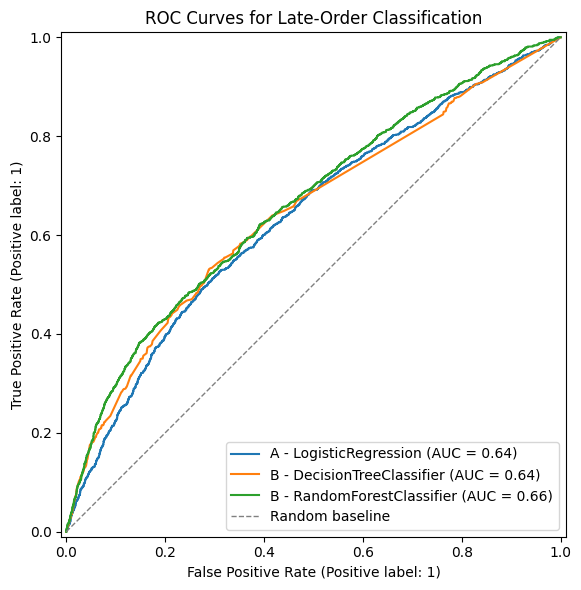

,model,threshold,true_late_caught_tp,missed_late_fn,false_alarm_fp,true_on_time_tn,late_recall,late_precision,late_f1,flagged_late_share
0,A - LogisticRegression,0.50,635,539,4435,8862,0.54,0.13,0.20,0.35
1,A - LogisticRegression,0.40,804,370,6541,6756,0.68,0.11,0.19,0.51
2,A - LogisticRegression,0.30,943,231,8928,4369,0.80,0.10,0.17,0.68
3,A - LogisticRegression,0.20,1062,112,11001,2296,0.90,0.09,0.16,0.83
4,B - DecisionTreeClassifier,0.50,590,584,3669,9628,0.50,0.14,0.22,0.29
5,B - DecisionTreeClassifier,0.40,697,477,4910,8387,0.59,0.12,0.21,0.39
6,B - DecisionTreeClassifier,0.30,997,177,10148,3149,0.85,0.09,0.16,0.77
7,B - DecisionTreeClassifier,0.20,1030,144,10471,2826,0.88,0.09,0.16,0.79
8,B - RandomForestClassifier,0.50,498,676,2546,10751,0.42,0.16,0.24,0.21
9,B - RandomForestClassifier,0.40,765,409,5752,7545,0.65,0.12,0.20,0.45


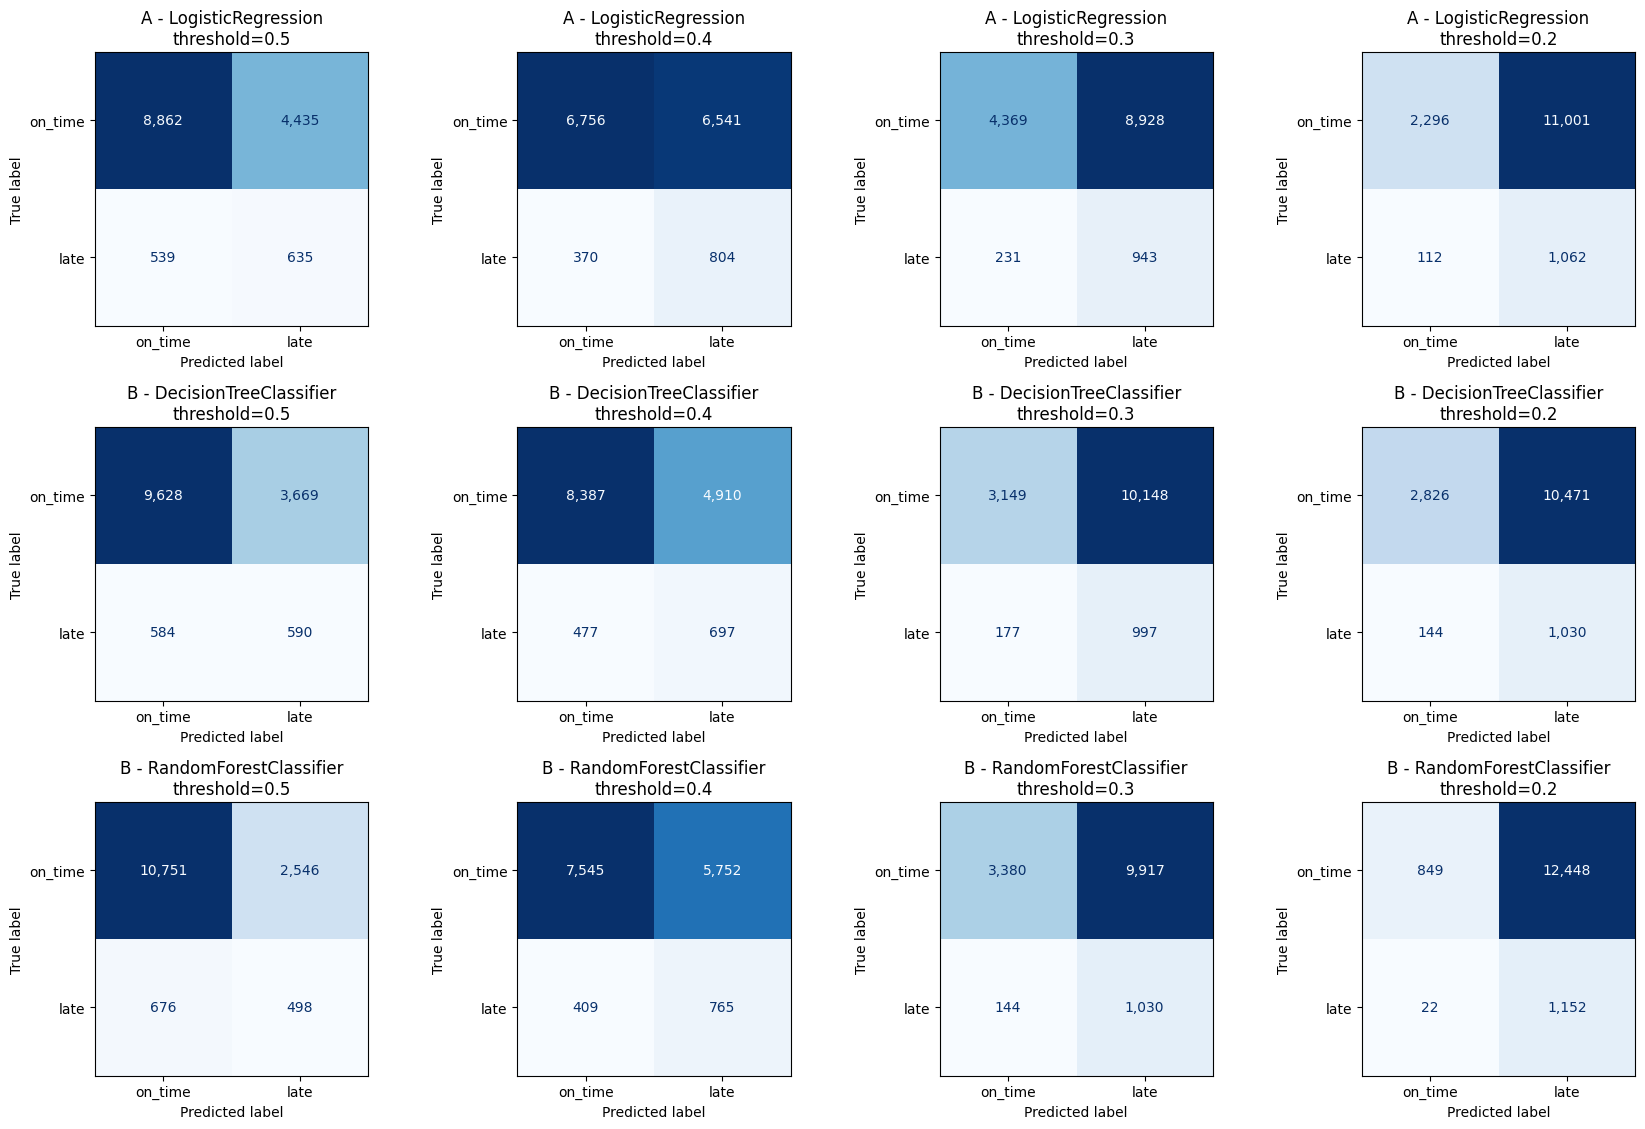

In [81]:
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score
)


def adjusted_r2_score(r2, n_rows, n_features):
    if n_rows <= n_features + 1:
        return np.nan
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def make_pipeline(estimator):
    return Pipeline(steps=[
        ('preprocess', preprocessor),
        ('model', estimator)
    ])


def get_positive_class_scores(model, X_data):
    if hasattr(model.named_steps['model'], 'predict_proba'):
        return model.predict_proba(X_data)[:, 1]
    if hasattr(model.named_steps['model'], 'decision_function'):
        return model.decision_function(X_data)
    return None


def evaluate_fitted_regression_model(name, model):
    predictions = model.predict(X_test)
    transformed_test = model.named_steps['preprocess'].transform(X_test)
    n_rows, n_features = transformed_test.shape
    r2 = r2_score(y_regression_test, predictions)

    return {
        'model': name,
        'transformed_features': n_features,
        'mae': mean_absolute_error(y_regression_test, predictions),
        'rmse': np.sqrt(mean_squared_error(y_regression_test, predictions)),
        'r2': r2,
        'adjusted_r2': adjusted_r2_score(r2, n_rows, n_features)
    }


def evaluate_fitted_classification_model(name, model, threshold=0.5):
    positive_scores = get_positive_class_scores(model, X_test)
    if positive_scores is not None:
        predictions = positive_scores >= threshold
    else:
        predictions = model.predict(X_test)

    result = {
        'model': name,
        'threshold': threshold,
        'accuracy': accuracy_score(y_classification_test, predictions),
        'balanced_accuracy': balanced_accuracy_score(y_classification_test, predictions),
        'precision_late': precision_score(y_classification_test, predictions, zero_division=0),
        'recall_late': recall_score(y_classification_test, predictions, zero_division=0),
        'f1_late': f1_score(y_classification_test, predictions, zero_division=0),
        'f1_macro': f1_score(y_classification_test, predictions, average='macro')
    }

    if positive_scores is not None:
        result['roc_auc'] = roc_auc_score(y_classification_test, positive_scores)
        result['pr_auc'] = average_precision_score(y_classification_test, positive_scores)
    else:
        result['roc_auc'] = np.nan
        result['pr_auc'] = np.nan

    return result


def fit_and_evaluate_regression_model(name, estimator):
    model = make_pipeline(estimator)
    model.fit(X_train, y_regression_train)
    return evaluate_fitted_regression_model(name, model), model


def fit_and_evaluate_classification_model(name, estimator):
    model = make_pipeline(estimator)
    model.fit(X_train, y_classification_train)
    return evaluate_fitted_classification_model(name, model), model


regression_models = {
    'A - LinearRegression': LinearRegression(),
    'A - Ridge': Ridge(alpha=1.0),
    'B - DecisionTreeRegressor': DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=50,
        random_state=42
    ),
    'B - RandomForestRegressor': RandomForestRegressor(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    )
}

classification_models = {
    'A - LogisticRegression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),
    'B - DecisionTreeClassifier': DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=50,
        class_weight='balanced',
        random_state=42
    ),
    'B - RandomForestClassifier': RandomForestClassifier(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

regression_results = []
fitted_regression_models = {}
for name, estimator in regression_models.items():
    result, model = fit_and_evaluate_regression_model(name, estimator)
    regression_results.append(result)
    fitted_regression_models[name] = model

classification_results = []
fitted_classification_models = {}
for name, estimator in classification_models.items():
    result, model = fit_and_evaluate_classification_model(name, estimator)
    classification_results.append(result)
    fitted_classification_models[name] = model

regression_results = pd.DataFrame(regression_results).sort_values('mae')
classification_results = pd.DataFrame(classification_results).sort_values(
    'pr_auc',
    ascending=False
)

display(regression_results)
display(classification_results)

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_classification_models.items():
    positive_scores = get_positive_class_scores(model, X_test)
    if positive_scores is not None:
        RocCurveDisplay.from_predictions(
            y_classification_test,
            positive_scores,
            name=name,
            ax=ax
        )
ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=1,
    label='Random baseline'
)
ax.set_title('ROC Curves for Late-Order Classification')
ax.legend()
plt.tight_layout()
plt.show()

thresholds = [0.5, 0.4, 0.3, 0.2]
threshold_results = []

for name, model in fitted_classification_models.items():
    late_scores = get_positive_class_scores(model, X_test)

    for threshold in thresholds:
        threshold_predictions = late_scores >= threshold
        tn, fp, fn, tp = confusion_matrix(
            y_classification_test,
            threshold_predictions,
            labels=[False, True]
        ).ravel()

        threshold_results.append({
            'model': name,
            'threshold': threshold,
            'true_late_caught_tp': tp,
            'missed_late_fn': fn,
            'false_alarm_fp': fp,
            'true_on_time_tn': tn,
            'late_recall': tp / (tp + fn) if (tp + fn) else np.nan,
            'late_precision': tp / (tp + fp) if (tp + fp) else np.nan,
            'late_f1': (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
            'flagged_late_share': (tp + fp) / (tp + fp + tn + fn)
        })

threshold_results = pd.DataFrame(threshold_results)
display(
    threshold_results.sort_values(
        ['model', 'threshold'],
        ascending=[True, False]
    )
)

n_models = len(fitted_classification_models)
n_thresholds = len(thresholds)
fig, axes = plt.subplots(
    n_models,
    n_thresholds,
    figsize=(4.3 * n_thresholds, 3.8 * n_models)
)

if n_models == 1:
    axes = np.array([axes])

for row_index, (name, model) in enumerate(fitted_classification_models.items()):
    late_scores = get_positive_class_scores(model, X_test)

    for col_index, threshold in enumerate(thresholds):
        ax = axes[row_index, col_index]
        threshold_predictions = late_scores >= threshold
        ConfusionMatrixDisplay.from_predictions(
            y_classification_test,
            threshold_predictions,
            labels=[False, True],
            display_labels=['on_time', 'late'],
            cmap='Blues',
            values_format=',',
            ax=ax,
            colorbar=False
        )
        ax.set_title(f'{name}\nthreshold={threshold}')

plt.tight_layout()
plt.show()


## Hyperparameter Tuning Methodology and Cross-Validation

Hyperparameters are tuned using cross-validation on the cleaned training data only. The holdout test set is not used during tuning. Regression models are selected primarily by cross-validated MAE because MAE is easy to interpret as average days of error. Classification models are selected primarily by PR-AUC because late deliveries are the minority class and the stakeholder cares about catching late cases.

To keep the notebook practical, cross-validation uses a stratified sample from the training data. After the best hyperparameters are selected, the chosen tuned models are refit on the full cleaned training set before final test evaluation.


In [82]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold

# Use a representative training sample for faster cross-validation.
tuning_sample_size = min(20000, len(X_train))
if len(X_train) > tuning_sample_size:
    _, X_tune, _, y_regression_tune, _, y_classification_tune = train_test_split(
        X_train,
        y_regression_train,
        y_classification_train,
        test_size=tuning_sample_size,
        random_state=42,
        stratify=y_classification_train
    )
else:
    X_tune = X_train.copy()
    y_regression_tune = y_regression_train.copy()
    y_classification_tune = y_classification_train.copy()

print(f'Cross-validation tuning sample: {len(X_tune):,} rows')

regression_cv = KFold(n_splits=3, shuffle=True, random_state=42)
classification_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

regression_tuning_specs = {
    'Tuned Ridge': {
        'estimator': Ridge(),
        'param_grid': {
            'model__alpha': [0.1, 1.0, 10.0, 50.0]
        }
    },
    'Tuned RandomForestRegressor': {
        'estimator': RandomForestRegressor(random_state=42, n_jobs=-1),
        'param_grid': {
            'model__n_estimators': [40],
            'model__max_depth': [12],
            'model__min_samples_leaf': [20, 50]
        }
    }
}

classification_tuning_specs = {
    'Tuned LogisticRegression': {
        'estimator': LogisticRegression(max_iter=1000, class_weight='balanced'),
        'param_grid': {
            'model__C': [0.1, 1.0, 10.0]
        }
    },
    'Tuned RandomForestClassifier': {
        'estimator': RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced'),
        'param_grid': {
            'model__n_estimators': [40],
            'model__max_depth': [12],
            'model__min_samples_leaf': [20, 50]
        }
    }
}

regression_searches = {}
regression_cv_rows = []
for name, spec in regression_tuning_specs.items():
    search = GridSearchCV(
        estimator=make_pipeline(spec['estimator']),
        param_grid=spec['param_grid'],
        scoring={
            'mae': 'neg_mean_absolute_error',
            'rmse': 'neg_root_mean_squared_error',
            'r2': 'r2'
        },
        refit='mae',
        cv=regression_cv,
        n_jobs=1
    )
    search.fit(X_tune, y_regression_tune)
    regression_searches[name] = search
    best_idx = search.best_index_
    regression_cv_rows.append({
        'model': name,
        'best_params': search.best_params_,
        'cv_mae': -search.cv_results_['mean_test_mae'][best_idx],
        'cv_rmse': -search.cv_results_['mean_test_rmse'][best_idx],
        'cv_r2': search.cv_results_['mean_test_r2'][best_idx]
    })

classification_searches = {}
classification_cv_rows = []
for name, spec in classification_tuning_specs.items():
    search = GridSearchCV(
        estimator=make_pipeline(spec['estimator']),
        param_grid=spec['param_grid'],
        scoring={
            'precision_late': 'precision',
            'recall_late': 'recall',
            'f1_late': 'f1',
            'roc_auc': 'roc_auc',
            'pr_auc': 'average_precision'
        },
        refit='pr_auc',
        cv=classification_cv,
        n_jobs=1
    )
    search.fit(X_tune, y_classification_tune)
    classification_searches[name] = search
    best_idx = search.best_index_
    classification_cv_rows.append({
        'model': name,
        'best_params': search.best_params_,
        'cv_precision_late': search.cv_results_['mean_test_precision_late'][best_idx],
        'cv_recall_late': search.cv_results_['mean_test_recall_late'][best_idx],
        'cv_f1_late': search.cv_results_['mean_test_f1_late'][best_idx],
        'cv_roc_auc': search.cv_results_['mean_test_roc_auc'][best_idx],
        'cv_pr_auc': search.cv_results_['mean_test_pr_auc'][best_idx]
    })

regression_cv_results = pd.DataFrame(regression_cv_rows).sort_values('cv_mae')
classification_cv_results = pd.DataFrame(classification_cv_rows).sort_values('cv_pr_auc', ascending=False)

display(regression_cv_results)
display(classification_cv_results)


Cross-validation tuning sample: 20,000 rows


,model,best_params,cv_mae,cv_rmse,cv_r2
1,Tuned RandomForestRegressor,"{'model__max_depth': 12, 'model__min_samples_l...",3.60,4.70,0.38
0,Tuned Ridge,{'model__alpha': 10.0},3.62,4.71,0.38


,model,best_params,cv_precision_late,cv_recall_late,cv_f1_late,cv_roc_auc,cv_pr_auc
1,Tuned RandomForestClassifier,"{'model__max_depth': 12, 'model__min_samples_l...",0.11,0.41,0.17,0.71,0.12
0,Tuned LogisticRegression,{'model__C': 0.1},0.08,0.64,0.14,0.69,0.09


## Tuned Model Evaluation and Final Selection

The best cross-validated estimator from each tuned family is refit by `GridSearchCV` on the full cleaned training set and evaluated once on the untouched test set. For classification, threshold choice is evaluated separately because the business cost of missing a late order is higher than the cost of reviewing some extra false alarms.


,model,transformed_features,mae,rmse,r2,adjusted_r2
1,Tuned RandomForestRegressor,176,4.70,8.12,0.25,0.24
0,Tuned Ridge,176,4.72,8.08,0.26,0.25


,model,threshold,accuracy,balanced_accuracy,precision_late,recall_late,f1_late,f1_macro,roc_auc,pr_auc
1,Tuned RandomForestClassifier,0.50,0.74,0.61,0.14,0.46,0.22,0.53,0.65,0.15
0,Tuned LogisticRegression,0.50,0.66,0.60,0.13,0.54,0.20,0.49,0.64,0.14


,model,transformed_features,mae,rmse,r2,adjusted_r2,stage
0,B - RandomForestRegressor,176,4.65,8.06,0.26,0.25,baseline
4,Tuned RandomForestRegressor,176,4.70,8.12,0.25,0.24,tuned
1,A - LinearRegression,176,4.72,8.08,0.26,0.25,baseline
2,A - Ridge,176,4.72,8.08,0.26,0.25,baseline
5,Tuned Ridge,176,4.72,8.08,0.26,0.25,tuned
3,B - DecisionTreeRegressor,176,4.79,8.19,0.24,0.23,baseline


,model,threshold,accuracy,balanced_accuracy,precision_late,recall_late,f1_late,f1_macro,roc_auc,pr_auc,stage
0,B - RandomForestClassifier,0.50,0.78,0.62,0.16,0.42,0.24,0.55,0.66,0.16,baseline
3,Tuned RandomForestClassifier,0.50,0.74,0.61,0.14,0.46,0.22,0.53,0.65,0.15,tuned
1,B - DecisionTreeClassifier,0.50,0.71,0.61,0.14,0.50,0.22,0.52,0.64,0.15,baseline
2,A - LogisticRegression,0.50,0.66,0.60,0.13,0.54,0.20,0.49,0.64,0.14,baseline
4,Tuned LogisticRegression,0.50,0.66,0.60,0.13,0.54,0.20,0.49,0.64,0.14,tuned


,model,threshold,true_late_caught_tp,missed_late_fn,false_alarm_fp,true_on_time_tn,late_recall,late_precision,late_f1,flagged_late_share
0,Tuned RandomForestClassifier,0.50,540,634,3185,10112,0.46,0.14,0.22,0.26
1,Tuned RandomForestClassifier,0.40,846,328,7408,5889,0.72,0.10,0.18,0.57
2,Tuned RandomForestClassifier,0.30,1083,91,11333,1964,0.92,0.09,0.16,0.86
3,Tuned RandomForestClassifier,0.20,1169,5,13125,172,1.00,0.08,0.15,0.99


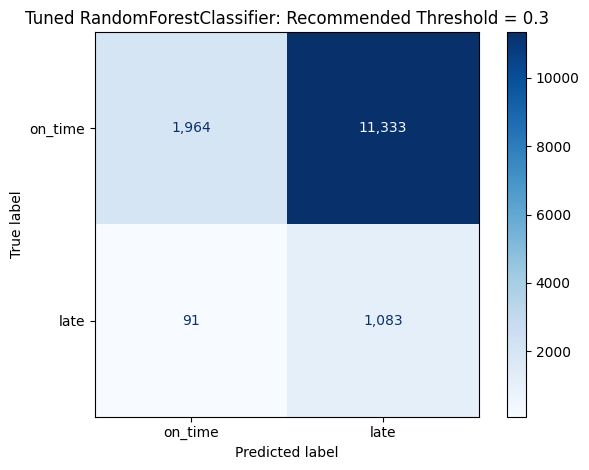

In [83]:
def refit_best_model_on_full_training_data(spec, best_params, X_fit, y_fit):
    model = make_pipeline(clone(spec['estimator']))
    model.set_params(**best_params)
    model.fit(X_fit, y_fit)
    return model


tuned_regression_results = []
tuned_regression_models = {}
for name, search in regression_searches.items():
    model = refit_best_model_on_full_training_data(
        regression_tuning_specs[name],
        search.best_params_,
        X_train,
        y_regression_train
    )
    tuned_regression_models[name] = model
    tuned_regression_results.append(evaluate_fitted_regression_model(name, model))

tuned_classification_results = []
tuned_classification_models = {}
for name, search in classification_searches.items():
    model = refit_best_model_on_full_training_data(
        classification_tuning_specs[name],
        search.best_params_,
        X_train,
        y_classification_train
    )
    tuned_classification_models[name] = model
    tuned_classification_results.append(evaluate_fitted_classification_model(name, model))

tuned_regression_results = pd.DataFrame(tuned_regression_results).sort_values('mae')
tuned_classification_results = pd.DataFrame(tuned_classification_results).sort_values('pr_auc', ascending=False)

display(tuned_regression_results)
display(tuned_classification_results)

all_regression_results = pd.concat([
    regression_results.assign(stage='baseline'),
    tuned_regression_results.assign(stage='tuned')
], ignore_index=True).sort_values('mae')

all_classification_results = pd.concat([
    classification_results.assign(stage='baseline'),
    tuned_classification_results.assign(stage='tuned')
], ignore_index=True).sort_values('pr_auc', ascending=False)

display(all_regression_results)
display(all_classification_results)

# Business threshold comparison for the best tuned classifier by PR-AUC.
best_classifier_name = tuned_classification_results.iloc[0]['model']
best_classifier = tuned_classification_models[best_classifier_name]
best_late_scores = get_positive_class_scores(best_classifier, X_test)

final_threshold_rows = []
for threshold in thresholds:
    preds = best_late_scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y_classification_test, preds, labels=[False, True]).ravel()
    final_threshold_rows.append({
        'model': best_classifier_name,
        'threshold': threshold,
        'true_late_caught_tp': tp,
        'missed_late_fn': fn,
        'false_alarm_fp': fp,
        'true_on_time_tn': tn,
        'late_recall': tp / (tp + fn) if (tp + fn) else np.nan,
        'late_precision': tp / (tp + fp) if (tp + fp) else np.nan,
        'late_f1': (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
        'flagged_late_share': (tp + fp) / (tp + fp + tn + fn)
    })

final_threshold_results = pd.DataFrame(final_threshold_rows)
display(final_threshold_results)

recommended_threshold = 0.3
recommended_predictions = best_late_scores >= recommended_threshold

ConfusionMatrixDisplay.from_predictions(
    y_classification_test,
    recommended_predictions,
    labels=[False, True],
    display_labels=['on_time', 'late'],
    cmap='Blues',
    values_format=',',
)
plt.title(f'{best_classifier_name}: Recommended Threshold = {recommended_threshold}')
plt.tight_layout()
plt.show()


## Feature Importance and Interpretability Analysis

For interpretation, linear models are inspected using coefficient magnitude after preprocessing, while tree-based models are inspected using impurity-based feature importance. One-hot encoded features are included, so category-specific effects such as seller/customer state or product category can appear separately.

These importance tables should be read as model explanations, not causal effects. Features can be correlated, and operational decisions should combine model evidence with domain judgment.


Best tuned regressor: Tuned RandomForestRegressor


,feature,importance,abs_importance
9,log_num__max_seller_buyer_distance_km,0.62,0.62
10,log_num__max_shipping_deadline_days,0.10,0.10
37,cat__customer_state_SP,0.05,0.05
6,log_num__total_freight,0.03,0.03
40,cat__purchase_month_2,0.02,0.02
50,cat__purchase_month_12,0.02,0.02
22,cat__customer_state_MG,0.01,0.01
49,cat__purchase_month_11,0.01,0.01
41,cat__purchase_month_3,0.01,0.01
11,log_num__freight_ratio,0.01,0.01


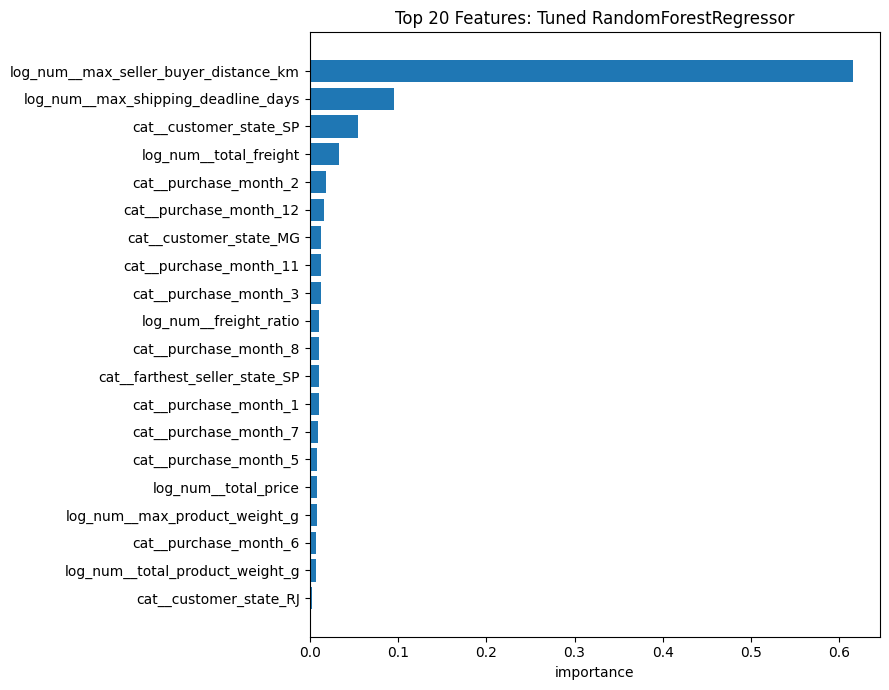

Best tuned classifier: Tuned RandomForestClassifier


,feature,importance,abs_importance
41,cat__purchase_month_3,0.10,0.10
44,cat__purchase_month_6,0.08,0.08
9,log_num__max_seller_buyer_distance_km,0.08,0.08
10,log_num__max_shipping_deadline_days,0.06,0.06
6,log_num__total_freight,0.05,0.05
46,cat__purchase_month_8,0.04,0.04
11,log_num__freight_ratio,0.04,0.04
5,log_num__total_price,0.04,0.04
175,cat__farthest_seller_state_SP,0.03,0.03
8,log_num__max_product_weight_g,0.03,0.03


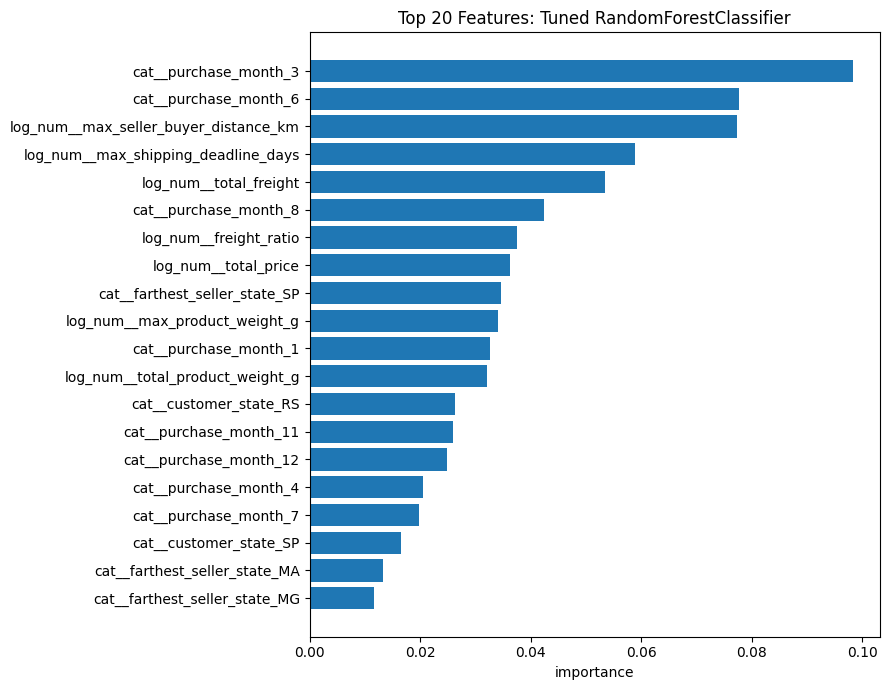

In [84]:
def get_transformed_feature_names(model):
    return model.named_steps['preprocess'].get_feature_names_out()


def display_top_feature_importance(model, model_name, top_n=20):
    feature_names = get_transformed_feature_names(model)
    estimator = model.named_steps['model']

    if hasattr(estimator, 'feature_importances_'):
        importance_values = estimator.feature_importances_
        importance_label = 'importance'
    elif hasattr(estimator, 'coef_'):
        importance_values = np.ravel(estimator.coef_)
        importance_label = 'coefficient'
    else:
        print(f'{model_name} does not expose coefficients or feature_importances_.')
        return None

    importance_df = pd.DataFrame({
        'feature': feature_names,
        importance_label: importance_values,
        'abs_importance': np.abs(importance_values)
    }).sort_values('abs_importance', ascending=False).head(top_n)

    display(importance_df)

    plot_col = importance_label
    plot_data = importance_df.sort_values('abs_importance')
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(plot_data['feature'], plot_data[plot_col])
    ax.set_title(f'Top {top_n} Features: {model_name}')
    ax.set_xlabel(plot_col)
    plt.tight_layout()
    plt.show()

    return importance_df

best_regressor_name = tuned_regression_results.iloc[0]['model']
best_regressor = tuned_regression_models[best_regressor_name]

best_classifier_name = tuned_classification_results.iloc[0]['model']
best_classifier = tuned_classification_models[best_classifier_name]

print(f'Best tuned regressor: {best_regressor_name}')
best_regression_importance = display_top_feature_importance(best_regressor, best_regressor_name)

print(f'Best tuned classifier: {best_classifier_name}')
best_classification_importance = display_top_feature_importance(best_classifier, best_classifier_name)


## Model Comparison and Final Selection

Use the displayed results to choose one model for each stakeholder problem:

- For **delivery-days regression**, prefer the model with the lowest test MAE/RMSE, while checking that R² is not meaningfully worse than alternatives.
- For **late-order classification**, prefer the model with stronger PR-AUC and recall for the late class. Because the logistics team wants fewer missed late orders, the final threshold can be lower than 0.5 if the resulting workload is acceptable.
- If a tuned model does not beat the baseline on the holdout test set, keep the baseline. Tuning is a search process, not a guarantee of improvement; with a small tuning grid or sampled cross-validation, the selected parameters can be more conservative than the original baseline.
- The current recommended starting threshold is `0.3` for the selected tuned classifier only if the team can handle the review volume shown in `flagged_late_share`. If capacity is tighter, compare `0.4` and `0.5`.

No voting or stacking ensemble is used in this notebook. That keeps the final recommendation easier to explain and maintain; an ensemble can be added later if the tuned baseline models are not strong enough.


## Actionable Insights for the E-Commerce Stakeholder

- Prioritize monitoring routes with long seller-buyer distance, high freight ratio, heavier products, and seller/customer geography patterns that appear important in the selected model.
- Use the classification model as a triage tool, not as an automatic decision maker. A lower threshold catches more late orders but increases the number of false alarms the logistics team must review.
- Review the threshold table with operations stakeholders. If capacity is limited, choose a threshold with a manageable `flagged_late_share`; if customer-delay prevention is more important, choose a threshold with higher `late_recall`.
- Use regression predictions to estimate expected delivery days and classification predictions to prioritize intervention. The two outputs answer different operational questions.


## Limitations and Constraints

- The dataset is historical Olist marketplace data, so model performance may not transfer perfectly to another country, time period, or logistics network.
- Some engineered features depend on order/item/seller information being available at prediction time. A production model would need the same fields before fulfilment begins.
- Median zip-prefix coordinates approximate location and may hide within-prefix geographic variation.
- `is_late` is based on Olist's estimated delivery date. That estimate is not used as a predictor, but it still defines the classification label.
- Feature importance is associative, not causal. Important features identify useful signals but do not prove that changing the feature will change delivery time.
- Outlier handling removes extreme delivery/shipping-deadline records from training only. These cases may need a separate operational process if they represent unusual but important failures.
